# Инженерия и отбор признаков: Employee Attrition
Вариант 14. Сравниваем импутацию, LOF и отбор MI/XGBoost на IBM HR. Все решения принимаются по 5-fold ROC-AUC на train; test открывается один раз в конце. Исходный учебный датасет синтетический и не описывает причин увольнений реальных сотрудников.

In [1]:
from pathlib import Path
import sys, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.experimental import enable_iterative_imputer
from sklearn.base import clone
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer, KNNImputer, IterativeImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from imblearn.pipeline import Pipeline as ResamplingPipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.feature_selection import SelectKBest, mutual_info_classif, SelectFromModel
from sklearn.decomposition import PCA
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score, average_precision_score, ConfusionMatrixDisplay
from xgboost import XGBClassifier
from functools import partial
import joblib
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
from src.features.outliers import HRFeatures, LOFResampler, mixed_mutual_information
SEED = 42
plt.rcParams['figure.figsize'] = (9, 4)
raw_path = PROJECT_ROOT / 'data/raw/WA_Fn-UseC_-HR-Employee-Attrition.csv'
raw = pd.read_csv(raw_path)
assert raw.shape == (1470, 35)
print('Raw shape:', raw.shape, 'Missing:', raw.isna().sum().sum())
display(raw.head())

Raw shape: (1470, 35) Missing: 0


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


Прежде любых сравнений фиксируем стратифицированный split 80/20. В каждой части независимо моделируем MCAR: случайно скрываем 12% значений MonthlyIncome, TotalWorkingYears, YearsAtCompany, без обращения к Attrition. В каждой колонке добавляем по 8 выбросов на train и по 2 на test с множителями 8, 6, 5 соответственно, выбирая только наблюдаемые значения. Это контролируемый стресс-тест, а не утверждение об отсутствии естественных аномалий. Test далее не участвует в подборе.
EmployeeNumber — идентификатор, EmployeeCount, Over18, StandardHours — константы схемы: исключаем их до моделирования.

In [2]:
target = raw.Attrition.map({'No': 0, 'Yes': 1})
train_ids, test_ids = train_test_split(raw.index, test_size=0.2, stratify=target, random_state=SEED)
drop_columns = ['Attrition', 'EmployeeNumber', 'EmployeeCount', 'Over18', 'StandardHours']
missing_columns = ['MonthlyIncome', 'TotalWorkingYears', 'YearsAtCompany']
def corrupt(frame, seed, count):
    frame = frame.copy()
    rng = np.random.default_rng(seed)
    for column in missing_columns:
        frame[column] = frame[column].astype(float)
        mask = rng.choice(frame.index, round(0.12 * len(frame)), replace=False)
        frame.loc[mask, column] = np.nan
    for column, multiplier in zip(missing_columns, [8, 6, 5]):
        candidates = frame.index[frame[column].notna()]
        selected = rng.choice(candidates, count, replace=False)
        frame.loc[selected, column] *= multiplier
    return frame
X_train = corrupt(raw.loc[train_ids].drop(columns=drop_columns), SEED, 8)
X_test = corrupt(raw.loc[test_ids].drop(columns=drop_columns), SEED + 1, 2)
y_train, y_test = target.loc[train_ids], target.loc[test_ids]
assert set(X_train.index).isdisjoint(X_test.index)
print('Train/test:', X_train.shape, X_test.shape)
display(X_train[missing_columns].isna().agg(['sum', 'mean']))
processed = pd.concat([X_train.assign(Attrition=y_train, split='train'), X_test.assign(Attrition=y_test, split='test')])
processed.index.name = 'source_row'
processed.to_csv(PROJECT_ROOT / 'data/processed/employee_attrition_corrupted.csv')

Train/test: (1176, 30) (294, 30)


,MonthlyIncome,TotalWorkingYears,YearsAtCompany
sum,141.000000,141.000000,141.000000
mean,0.119898,0.119898,0.119898


Масштабирование числовых признаков выполняется **перед** импутацией, включая KNN и Iterative: StandardScaler поддерживает NaN. Категории кодируются внутри каждого fold. Iterative использует RandomForestRegressor (20 деревьев, глубина 6, до 5 итераций); всё обучение выполняется только на обучающей части fold. Сравниваем одинаковую логистическую регрессию с balanced class weights.

In [3]:
imputers = {
    'median': SimpleImputer(strategy='median'),
    'knn': KNNImputer(n_neighbors=5, weights='distance'),
    'iterative': IterativeImputer(estimator=RandomForestRegressor(n_estimators=20, max_depth=6, random_state=SEED, n_jobs=1), max_iter=5, skip_complete=True, random_state=SEED, initial_strategy='median'),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
def preprocess(method):
    return ColumnTransformer([
        ('numeric', Pipeline([('scale', StandardScaler()), ('impute', clone(imputers[method]))]), make_column_selector(dtype_include=np.number)),
        ('categorical', Pipeline([('impute', SimpleImputer(strategy='most_frequent')), ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), make_column_selector(dtype_exclude=np.number)),
    ])
def build(method, engineered=False, outliers=False, selection='none'):
    steps = [('features', HRFeatures() if engineered else 'passthrough'), ('preprocess', preprocess(method))]
    if outliers:
        steps.append(('outliers', LOFResampler()))
    if selection == 'mi':
        steps.append(('selection', SelectKBest(mixed_mutual_information, k=30)))
    elif selection == 'xgb':
        steps.append(('selection', SelectFromModel(XGBClassifier(n_estimators=80, max_depth=3, learning_rate=0.08, subsample=0.9, colsample_bytree=0.9, random_state=SEED, n_jobs=1, eval_metric='logloss'), threshold='median')))
    steps.append(('classifier', LogisticRegression(max_iter=2000, class_weight='balanced', random_state=SEED)))
    return ResamplingPipeline(steps)
def evaluate_cv(pipeline):
    return cross_val_score(pipeline, X_train, y_train, cv=cv, scoring='roc_auc', n_jobs=1, error_score='raise')
imputation_scores = {name: evaluate_cv(build(name)) for name in imputers}
imputation_table = pd.DataFrame([{'method': name, 'ROC_AUC': scores.mean(), 'std': scores.std(), 'fold_scores': scores.tolist()} for name, scores in imputation_scores.items()]).sort_values('ROC_AUC', ascending=False)
display(imputation_table)
best_imputer = imputation_table.iloc[0]['method']
print('Selected imputation by train CV:', best_imputer)

C:\Users\t-pud\AppData\Local\Temp\prod-me-feature-engineering-20261023\.venv\Lib\site-packages\sklearn\impute\_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


C:\Users\t-pud\AppData\Local\Temp\prod-me-feature-engineering-20261023\.venv\Lib\site-packages\sklearn\impute\_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


C:\Users\t-pud\AppData\Local\Temp\prod-me-feature-engineering-20261023\.venv\Lib\site-packages\sklearn\impute\_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


C:\Users\t-pud\AppData\Local\Temp\prod-me-feature-engineering-20261023\.venv\Lib\site-packages\sklearn\impute\_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


C:\Users\t-pud\AppData\Local\Temp\prod-me-feature-engineering-20261023\.venv\Lib\site-packages\sklearn\impute\_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


,method,ROC_AUC,std,fold_scores
0,median,0.831983,0.031760,"[0.8124667729930888, 0.8000267165375367, 0.849..."
2,iterative,0.830835,0.032884,"[0.8115364167995747, 0.788004274646006, 0.8521..."
1,knn,0.828699,0.030704,"[0.8104731525784157, 0.7941490782794549, 0.839..."


Selected imputation by train CV: median


C:\Users\t-pud\AppData\Local\Temp\prod-me-feature-engineering-20261023\.venv\Lib\site-packages\sklearn\impute\_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


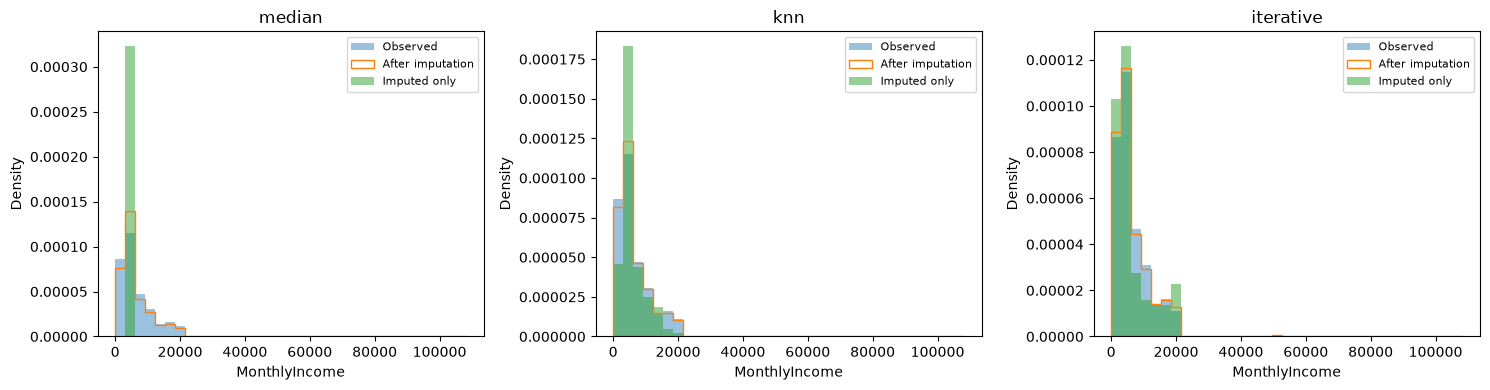

In [4]:
# Fit on train only; invert scaling so plots retain income units.
numeric_columns = X_train.select_dtypes(include=np.number).columns
income_pos = list(numeric_columns).index('MonthlyIncome')
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, method in zip(axes, imputers):
    numeric_pipeline = clone(preprocess(method).transformers[0][1])
    filled_scaled = numeric_pipeline.fit_transform(X_train[numeric_columns])
    filled = numeric_pipeline.named_steps['scale'].inverse_transform(filled_scaled)
    missing = X_train.MonthlyIncome.isna()
    observed = X_train.loc[~missing, 'MonthlyIncome']
    bins = np.linspace(0, max(observed.max(), filled[:, income_pos].max()) * 1.01, 36)
    ax.hist(observed, bins=bins, alpha=0.45, density=True, label='Observed')
    ax.hist(filled[:, income_pos], bins=bins, histtype='step', density=True, label='After imputation')
    ax.hist(filled[missing, income_pos], bins=bins, alpha=0.5, density=True, label='Imputed only')
    ax.set(title=method, xlabel='MonthlyIncome', ylabel='Density')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

LOF оценивает локальную плотность в масштабированном и закодированном пространстве. Доля 2.5% задаётся заранее как диагностический порог. PCA только визуализирует train; LOF работает до PCA. Сэмплер fit_resample синхронно удаляет X и y при fit, а imblearn.Pipeline пропускает его на predict: тестовые строки сохраняются. Не все аномалии ошибочны, поэтому полезность удаления отдельно проверяется CV.

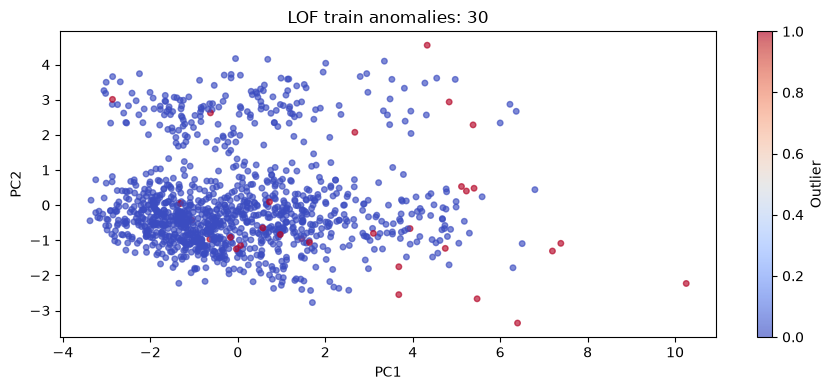

Rows removed: 30


In [5]:
diagnostic = preprocess(best_imputer)
train_matrix = diagnostic.fit_transform(X_train)
sampler = LOFResampler()
filtered_X, filtered_y = sampler.fit_resample(train_matrix, y_train)
assert len(filtered_X) == len(filtered_y) == sampler.inlier_mask_.sum()
assert np.array_equal(filtered_y, y_train.to_numpy()[sampler.inlier_mask_])
projection = PCA(n_components=2, random_state=SEED).fit_transform(train_matrix)
plt.scatter(projection[:, 0], projection[:, 1], c=~sampler.inlier_mask_, cmap='coolwarm', s=16, alpha=0.65)
plt.xlabel('PC1'); plt.ylabel('PC2'); plt.title(f'LOF train anomalies: {sampler.n_removed_}')
plt.colorbar(label='Outlier'); plt.tight_layout(); plt.show()
print('Rows removed:', sampler.n_removed_)

Для одиночной таблицы добавляем стаж до текущей роли и отношения дохода к стажу и уровню должности. Признаки вычисляются построчно до импутации; отрицательный стаж после искусственного повреждения не обрезаем, чтобы не скрывать аномалии. Сравниваем исходные признаки, ручные признаки, LOF и два разных отбора: фильтр mutual information (30 признаков) и встроенные важности XGBoost (порог median). Отбор обучается заново в каждом fold, а классификатор во всех опытах одинаков.

In [6]:
configurations = {
    'original': dict(engineered=False, outliers=False, selection='none'),
    'engineered': dict(engineered=True, outliers=False, selection='none'),
    'lof': dict(engineered=True, outliers=True, selection='none'),
    'mi': dict(engineered=True, outliers=True, selection='mi'),
    'xgb': dict(engineered=True, outliers=True, selection='xgb'),
}
feature_scores = {'original': imputation_scores[best_imputer]}
for name, config in configurations.items():
    if name != 'original':
        feature_scores[name] = evaluate_cv(build(best_imputer, **config))
feature_table = pd.DataFrame([{'configuration': name, 'ROC_AUC': scores.mean(), 'std': scores.std(), 'delta_original': scores.mean() - feature_scores['original'].mean(), 'fold_scores': scores.tolist()} for name, scores in feature_scores.items()]).sort_values('ROC_AUC', ascending=False)
display(feature_table)
# Assignment requires every stage in the final pipeline; choose MI or XGB by CV only.
full_candidates = feature_table[feature_table.configuration.isin(['mi', 'xgb'])]
best_selection = full_candidates.iloc[0]['configuration']
print('Best complete pipeline selection:', best_selection)
print('Best overall diagnostic configuration:', feature_table.iloc[0]['configuration'])

,configuration,ROC_AUC,std,delta_original,fold_scores
0,original,0.831983,0.031760,0.000000,"[0.8124667729930888, 0.8000267165375367, 0.849..."
1,engineered,0.828858,0.035784,-0.003125,"[0.8115364167995747, 0.7829281325140263, 0.846..."
2,lof,0.828225,0.035245,-0.003758,"[0.803960659223817, 0.7862676997061181, 0.8482..."
4,xgb,0.805104,0.041480,-0.026879,"[0.7616959064327485, 0.7614213197969543, 0.844..."
3,mi,0.795844,0.040472,-0.036139,"[0.7773790536948433, 0.7341704515094843, 0.826..."


Best complete pipeline selection: xgb
Best overall diagnostic configuration: original


Финальный конвейер содержит все обязательные стадии, поэтому между MI и XGBoost выбирается лучший по train CV, даже если диагностический вариант без удаления/отбора оказался лучше. Значения CV служат выбору и не являются независимой оценкой из-за нескольких сравнений. Единственная независимая оценка — фиксированный test ниже; порог 0.5 задан заранее, метрики accuracy/F1 зависят от него.

ROC_AUC              0.789043
accuracy             0.765306
F1                   0.473282
average_precision    0.583036
Name: untouched_test, dtype: float64

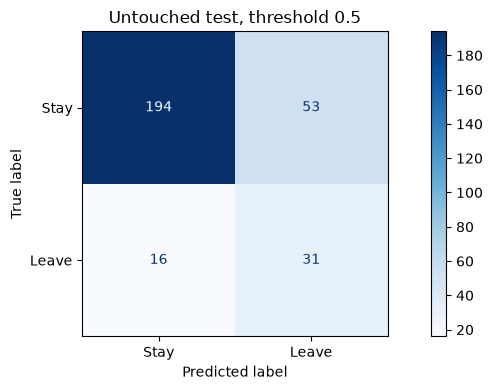

Encoded features: 54 Selected: 27


0                                       numeric__Age
1                   numeric__EnvironmentSatisfaction
2                            numeric__JobInvolvement
3                                  numeric__JobLevel
4                           numeric__JobSatisfaction
5                             numeric__MonthlyIncome
6                        numeric__NumCompaniesWorked
7                          numeric__StockOptionLevel
8                         numeric__TotalWorkingYears
9                           numeric__WorkLifeBalance
10                           numeric__YearsAtCompany
11                     numeric__YearsWithCurrManager
12                   numeric__YearsBeforeCurrentRole
13                        numeric__IncomePerJobLevel
14     categorical__BusinessTravel_Travel_Frequently
15    categorical__Department_Research & Development
16                     categorical__Department_Sales
17        categorical__JobRole_Laboratory Technician
18                      categorical__JobRole_M

Saved and reloaded: employee_attrition.joblib


In [7]:
final_pipeline = build(best_imputer, engineered=True, outliers=True, selection=best_selection)
final_pipeline.fit(X_train, y_train)
probability = final_pipeline.predict_proba(X_test)[:, 1]
prediction = final_pipeline.predict(X_test)
assert len(probability) == len(prediction) == len(X_test) == 294
metrics = {'ROC_AUC': roc_auc_score(y_test, probability), 'accuracy': accuracy_score(y_test, prediction), 'F1': f1_score(y_test, prediction), 'average_precision': average_precision_score(y_test, probability)}
display(pd.Series(metrics, name='untouched_test'))
ConfusionMatrixDisplay.from_predictions(y_test, prediction, display_labels=['Stay', 'Leave'], cmap='Blues')
plt.title('Untouched test, threshold 0.5'); plt.tight_layout(); plt.show()
feature_names = final_pipeline.named_steps['preprocess'].get_feature_names_out()
selector = final_pipeline.named_steps['selection']
selected_names = feature_names[selector.get_support()]
print('Encoded features:', len(feature_names), 'Selected:', len(selected_names))
display(pd.Series(selected_names, name='selected_features'))
model_path = PROJECT_ROOT / 'models/employee_attrition.joblib'
joblib.dump(final_pipeline, model_path)
reloaded = joblib.load(model_path)
np.testing.assert_allclose(reloaded.predict_proba(X_test), final_pipeline.predict_proba(X_test))
summary = {'seed': SEED, 'train_rows': len(X_train), 'test_rows': len(X_test), 'imputer': best_imputer, 'selection': best_selection, 'test_metrics': metrics}
(PROJECT_ROOT / 'models/employee_attrition_metrics.json').write_text(json.dumps(summary, indent=2), encoding='utf-8')
print('Saved and reloaded:', model_path.name)

In [8]:
best_overall = feature_table.iloc[0]
print(f"По train CV лучшая импутация: {best_imputer}; лучший диагностический вариант: {best_overall['configuration']} (ROC-AUC {best_overall['ROC_AUC']:.4f}).")
for name in ['engineered', 'lof', 'mi', 'xgb']:
    row = feature_table.set_index('configuration').loc[name]
    print(f"{name}: изменение относительно original = {row['delta_original']:+.4f}")
print(f"Полный конвейер ({best_selection}) на независимом test: ROC-AUC={metrics['ROC_AUC']:.4f}, AP={metrics['average_precision']:.4f}.")
print('Улучшения оцениваются по средним CV; небольшие различия при пересекающихся разбросах не доказывают превосходство. Искусственные искажения ограничивают переносимость выводов на исходную таблицу.')

По train CV лучшая импутация: median; лучший диагностический вариант: original (ROC-AUC 0.8320).
engineered: изменение относительно original = -0.0031
lof: изменение относительно original = -0.0038
mi: изменение относительно original = -0.0361
xgb: изменение относительно original = -0.0269
Полный конвейер (xgb) на независимом test: ROC-AUC=0.7890, AP=0.5830.
Улучшения оцениваются по средним CV; небольшие различия при пересекающихся разбросах не доказывают превосходство. Искусственные искажения ограничивают переносимость выводов на исходную таблицу.
